# ChronoClone — In Silico Validation

Tests the full **ChronoClone** pipeline on **pre-generated simulated data**
in `simulated_data/` (12 ground-truth metaclones, ODE-based differentiation).

Pipeline:
1. Load `simulated_clones_meta{1..12}.csv` → `final_table` with ground-truth labels
2. Expand clone counts → single-cell AnnData
3. `build_clone_table` → `normalize_clone_table` → `build_consensus_matrix` → `sweep_thresholds` → `transfer_metaclone_labels`
4. Evaluate recovery vs ground truth (ARI + confusion matrix)

## 0. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from anndata import AnnData
import chronoclone as cc

np.random.seed(42)

## 1. Constants

In [2]:
time = ['0', '4', '9', '15']
days = [0, 4, 9, 15]
pop  = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk_prog', 'MEMP',
        'GMP', 'GMDP', 'Mast_prog', 'Baso_prog', 'Neu_prog', 'DC_prog', 'Mono_prog']

# Column order matches simulation_generate.ipynb:
#   vec = ['Day' + j + '_Cluster' + i  for i in pop for j in time]
# → cell_type is the OUTER loop, time is the INNER loop
vec = ['Day' + j + '_Cluster' + i for i in pop for j in time]

DAYS_CTRL    = ['Day0', 'Day4', 'Day9', 'Day15']
DATA_DIR     = 'simulated_data'

## 2. Load Simulated Data

Each CSV has no header and 52 columns (13 cell types × 4 timepoints).
Columns follow the `vec` order above.
Clone IDs: `c{row_index}_mc{metaclone_number}` (zero-based per file).

In [3]:
df = []
for j in range(1, 13):
    temp = pd.read_csv(
        os.path.join(DATA_DIR, f'simulated_clones_meta{j}.csv'),
        header=None
    )
    temp.index = 'c' + temp.index.astype(str) + '_mc' + str(j)
    df.append(temp)

final_table = pd.concat(df)
final_table.columns = vec

# Per-timepoint totals and overall total
for day in days:
    day_cols = [col for col in final_table.columns if col.startswith(f'Day{day}_')]
    final_table[f'Day_{day}_Total'] = final_table[day_cols].sum(axis=1)

final_table['total_count'] = final_table[[f'Day_{day}_Total' for day in days]].sum(axis=1)

# Ground-truth labels (before filtering)
ground_truth_all = pd.Series(
    [idx.split('_mc')[1] for idx in final_table.index],
    index=final_table.index,
    name='metaclone_gt'
).apply(lambda x: f'mc{x}')

# Keep only clones with at least 1 cell total
final_table  = final_table[final_table['total_count'] > 1]
ground_truth = ground_truth_all.loc[final_table.index]

print(f'final_table shape  : {final_table.shape}')
print(f'Clones retained    : {len(final_table)}')
print(f'Ground-truth labels: {sorted(ground_truth.unique())}')
display(final_table.iloc[:3, :8])

final_table shape  : (517, 57)
Clones retained    : 517
Ground-truth labels: ['mc1', 'mc10', 'mc11', 'mc12', 'mc2', 'mc3', 'mc4', 'mc5', 'mc6', 'mc7', 'mc8', 'mc9']


,Day0_ClusterHSC,Day4_ClusterHSC,Day9_ClusterHSC,Day15_ClusterHSC,Day0_ClusterHSPC,Day4_ClusterHSPC,Day9_ClusterHSPC,Day15_ClusterHSPC
c0_mc1,13.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0
c1_mc1,9.0,-0.0,0.0,2.0,0.0,0.0,1.0,0.0
c2_mc1,14.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0


## 3. Build AnnData

Expand clone count table → single-cell AnnData with obs columns
`LARRY_ID`, `day`, `cell_type`, `condition`.

In [4]:
# Use only the 52 data columns (drop the Total/total_count helper columns)
data_cols = vec

cell_rows = []
for clone_id, row in final_table[data_cols].iterrows():
    for ct in pop:
        for t in time:
            col = f'Day{t}_Cluster{ct}'
            n = int(max(0, round(row[col])))
            for _ in range(n):
                cell_rows.append({
                    'LARRY_ID'  : clone_id,
                    'day'       : t,
                    'cell_type' : ct,
                    'condition' : 'C',
                })

obs = pd.DataFrame(cell_rows)
obs.index = obs.index.astype(str)

adata = AnnData(X=np.zeros((len(obs), 1)), obs=obs)
adata_ctrl = adata.copy()

print('adata_ctrl:', adata_ctrl)
print('Unique clones:', adata_ctrl.obs['LARRY_ID'].nunique())
display(adata_ctrl.obs.head(5))

adata_ctrl: AnnData object with n_obs × n_vars = 397836 × 1
    obs: 'LARRY_ID', 'day', 'cell_type', 'condition'
Unique clones: 517


,LARRY_ID,day,cell_type,condition
0,c0_mc1,0,HSC,C
1,c0_mc1,0,HSC,C
2,c0_mc1,0,HSC,C
3,c0_mc1,0,HSC,C
4,c0_mc1,0,HSC,C


## 4. Build & Normalise Clone Table

In [5]:
clone_table = cc.build_clone_table(
    adata_ctrl,
    clone_id_col   = 'LARRY_ID',
    time_col       = 'day',
    feature_col    = 'cell_type',
    times_order    = time,       # explicit: ['0','4','9','15']
    features_order = pop,
)
print('clone_table shape:', clone_table.shape)
display(clone_table.head(3))

clone_table shape: (517, 52)


,Day0_ClusterHSC,Day0_ClusterHSPC,Day0_ClusterMEP,Day0_ClusterCMP,Day0_ClusterMk_prog,Day0_ClusterMEMP,Day0_ClusterGMP,Day0_ClusterGMDP,Day0_ClusterMast_prog,Day0_ClusterBaso_prog,...,Day15_ClusterCMP,Day15_ClusterMk_prog,Day15_ClusterMEMP,Day15_ClusterGMP,Day15_ClusterGMDP,Day15_ClusterMast_prog,Day15_ClusterBaso_prog,Day15_ClusterNeu_prog,Day15_ClusterDC_prog,Day15_ClusterMono_prog
LARRY_ID,,,,,,,,,,,,,,,,,,,,,
c0_mc1,13,1,0,0,0,0,1,37,7,12,...,0,1,1,39,15,39,7,21,126,14
c0_mc10,4,1,0,0,0,0,1,47,0,0,...,0,1,1,122,0,0,51,2,2,0
c0_mc11,4,1,0,0,0,0,1,0,0,0,...,0,1,1,201,0,0,49,2,2,0


In [6]:
norm_table = cc.normalize_clone_table(
    clone_table,
    times_order    = DAYS_CTRL,
    features_order = pop,
)
print('norm_table shape:', norm_table.shape)
display(norm_table.head(3))

norm_table shape: (517, 52)


,Day0_ClusterHSC,Day0_ClusterHSPC,Day0_ClusterMEP,Day0_ClusterCMP,Day0_ClusterMk_prog,Day0_ClusterMEMP,Day0_ClusterGMP,Day0_ClusterGMDP,Day0_ClusterMast_prog,Day0_ClusterBaso_prog,...,Day15_ClusterCMP,Day15_ClusterMk_prog,Day15_ClusterMEMP,Day15_ClusterGMP,Day15_ClusterGMDP,Day15_ClusterMast_prog,Day15_ClusterBaso_prog,Day15_ClusterNeu_prog,Day15_ClusterDC_prog,Day15_ClusterMono_prog
LARRY_ID,,,,,,,,,,,,,,,,,,,,,
c0_mc1,0.058824,0.004525,0.0,0.0,0.0,0.0,0.004525,0.167421,0.031674,0.054299,...,0.0,0.003802,0.003802,0.148289,0.057034,0.148289,0.026616,0.079848,0.479087,0.053232
c0_mc10,0.014870,0.003717,0.0,0.0,0.0,0.0,0.003717,0.174721,0.000000,0.000000,...,0.0,0.005587,0.005587,0.681564,0.000000,0.000000,0.284916,0.011173,0.011173,0.000000
c0_mc11,0.011527,0.002882,0.0,0.0,0.0,0.0,0.002882,0.000000,0.000000,0.000000,...,0.0,0.003906,0.003906,0.785156,0.000000,0.000000,0.191406,0.007812,0.007812,0.000000


## 5. Consensus Matrix (Multi-Resolution Leiden)

In [7]:
filtered_table, traj_adata, consensus = cc.build_consensus_matrix(
    norm_table,
    min_cells    = 3,
    adata_full   = adata_ctrl,
    clone_id_col = 'LARRY_ID',
    resolutions  = np.arange(1.1, 4.1, 0.1),
    n_neighbors  = 15,
)
consensus_distance = 1 - consensus
print('Filtered clones :', filtered_table.shape[0])
print('Consensus matrix:', consensus.shape)

2026-06-25 13:04:36.225548: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-25 13:04:44.464455: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-25 13:05:21.921329: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Filtered clones : 517
Consensus matrix: (517, 517)


## 6. Threshold Sweep → Optimal Metaclone Labels

Starting threshold sweep...

Selected threshold : 0.62
Max silhouette score: 0.461
Clusters            : 12


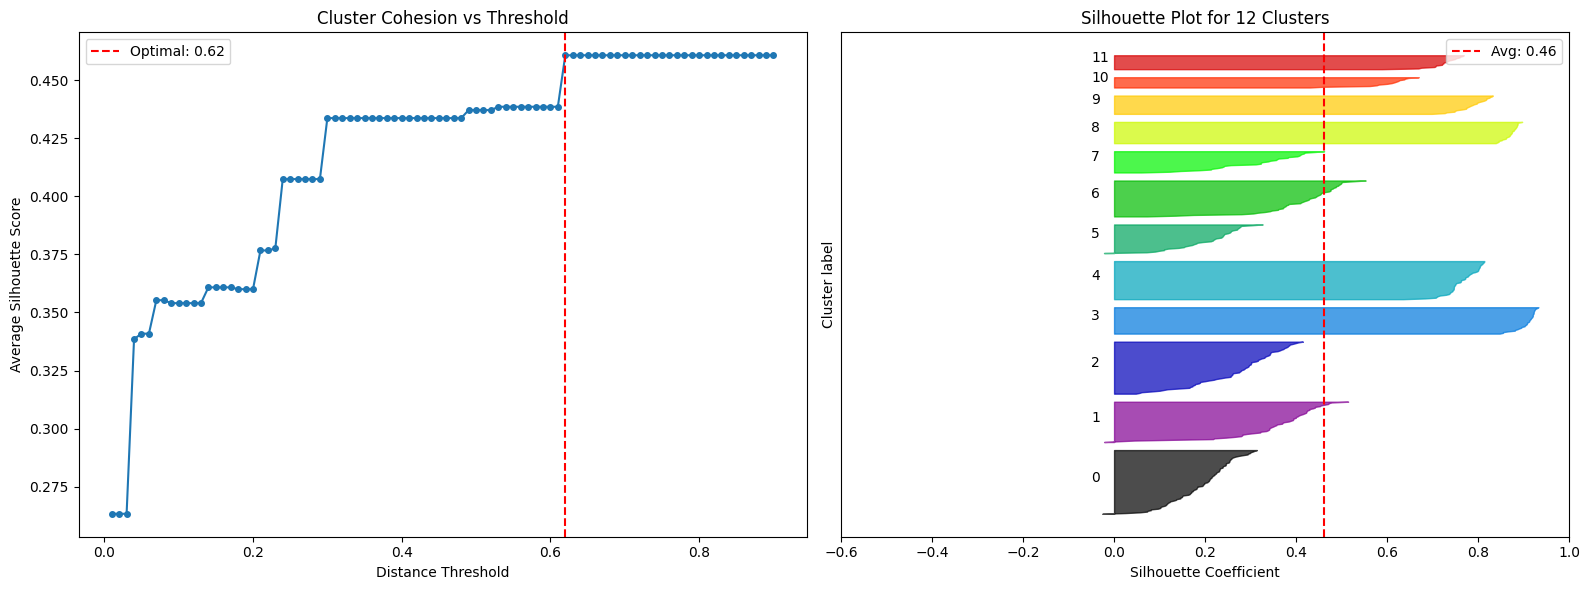

Optimal threshold  : 0.620
N metaclones found : 12


In [8]:
thresholds, sil_scores, counts, opt_thresh, final_labels, sample_sil = cc.sweep_thresholds(
    consensus_distance, filtered_table
)

# sweep_thresholds returns final_labels as a numpy.ndarray;
# wrap as a pandas Series indexed by clone IDs for downstream use
final_labels = pd.Series(final_labels, index=filtered_table.index, name='metaclone')

cc.plot_threshold_and_silhouette(
    thresholds, sil_scores, counts, opt_thresh, max(sil_scores),
    filtered_table, final_labels, sample_sil
)
plt.show()

print(f'Optimal threshold  : {opt_thresh:.3f}')
print(f'N metaclones found : {final_labels.nunique()}')

## 7. Transfer Labels → adata_ctrl

In [9]:
adata_ctrl = cc.transfer_metaclone_labels(
    adata_ctrl, traj_adata, final_labels, clone_id_col='LARRY_ID'
)
print('Metaclone label counts:')
display(adata_ctrl.obs['metaclone'].value_counts())

Metaclone label counts:


metaclone
0     71962
2     58916
1     45844
4     43636
6     40706
5     32983
8     25171
7     24754
9     21474
11    16149
10    12150
3      4091
Name: count, dtype: int64

## 8. Metaclone Dynamics

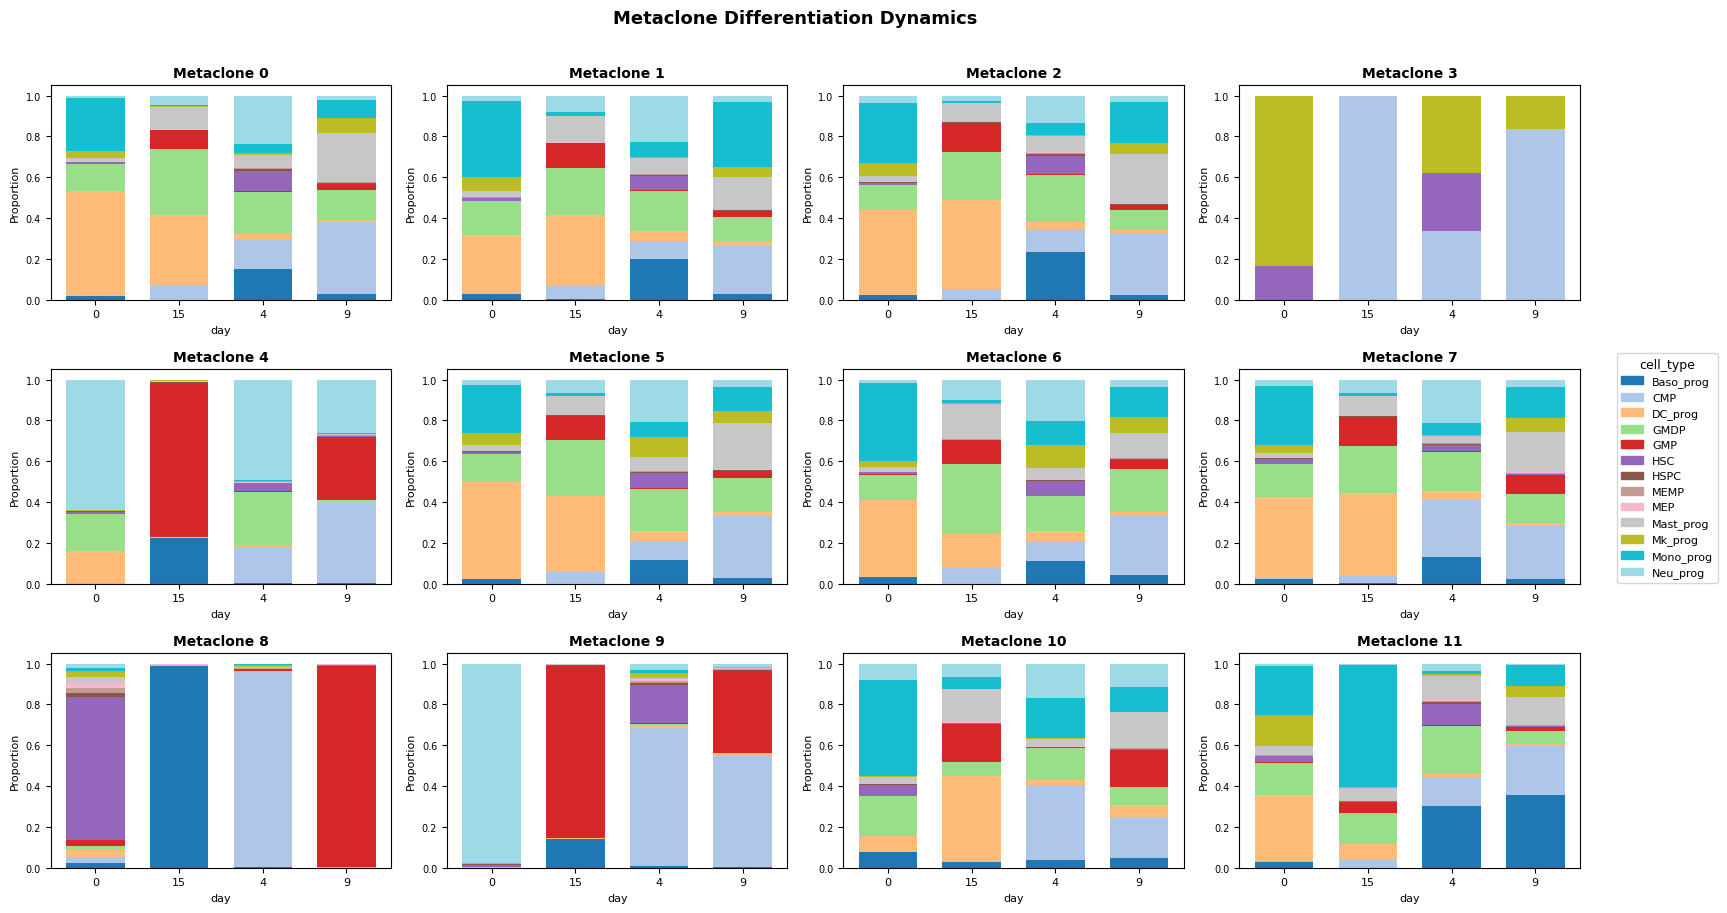

In [10]:
cc.plot_metaclone_dynamics(
    adata_ctrl,
    metaclone_key = 'metaclone',
    time_key      = 'day',
    feature_key   = 'cell_type',
)
plt.show()

## 9. Accuracy vs Ground Truth

Evaluate metaclone recovery using **Adjusted Rand Index (ARI)** and a **confusion matrix**.

In [11]:
from sklearn.metrics import adjusted_rand_score

clone_gt   = ground_truth.loc[filtered_table.index]
clone_pred = final_labels.astype(str)

ari = adjusted_rand_score(clone_gt, clone_pred)
print(f'Adjusted Rand Index (ARI): {ari:.4f}  (1.0 = perfect recovery)')

Adjusted Rand Index (ARI): 1.0000  (1.0 = perfect recovery)


ChronoClone,0,1,10,11,2,3,4,5,6,7,8,9
Ground Truth,,,,,,,,,,,,
mc1,0,0,15,0,0,0,0,0,0,0,0,0
mc10,0,0,0,0,0,0,53,0,0,0,0,0
mc11,0,0,0,0,0,0,0,0,0,0,0,26
mc12,0,0,0,0,0,0,0,0,0,0,30,0
mc2,0,0,0,0,0,0,0,0,0,30,0,0
mc3,0,0,0,0,0,0,0,0,50,0,0,0
mc4,0,0,0,0,0,0,0,40,0,0,0,0
mc5,0,0,0,0,72,0,0,0,0,0,0,0
mc6,0,56,0,0,0,0,0,0,0,0,0,0


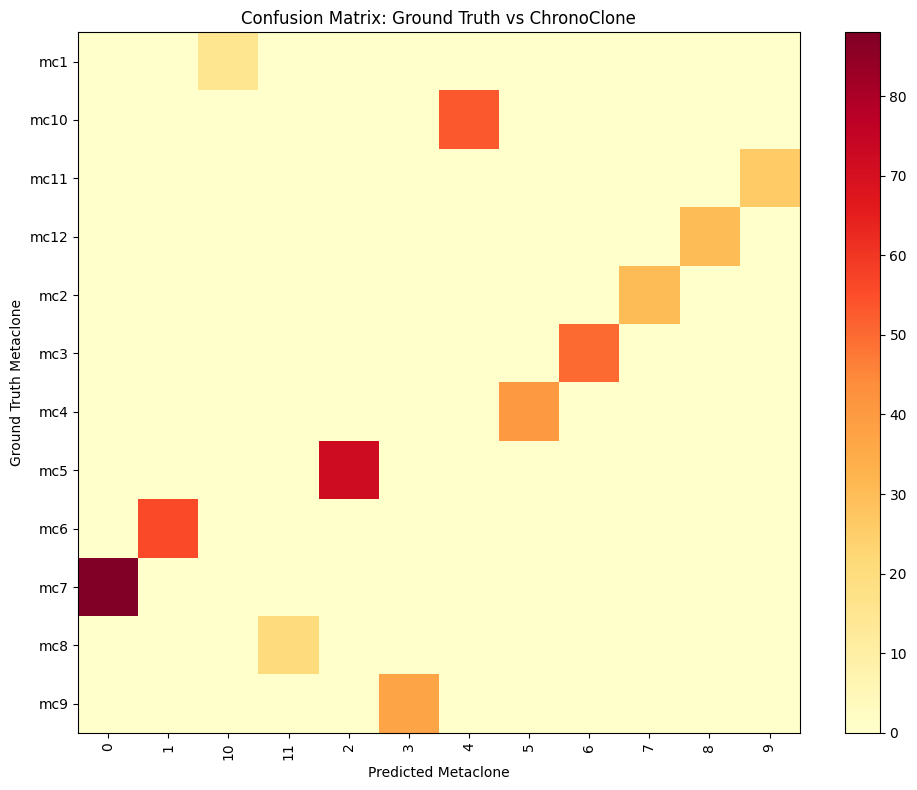

In [12]:
conf = pd.crosstab(
    clone_gt.rename('Ground Truth'),
    clone_pred.rename('ChronoClone'),
)
display(conf)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(conf.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(conf.columns)))
ax.set_yticks(range(len(conf.index)))
ax.set_xticklabels(conf.columns, rotation=90)
ax.set_yticklabels(conf.index)
ax.set_xlabel('Predicted Metaclone')
ax.set_ylabel('Ground Truth Metaclone')
ax.set_title('Confusion Matrix: Ground Truth vs ChronoClone')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 10. Consensus Distance Heatmap

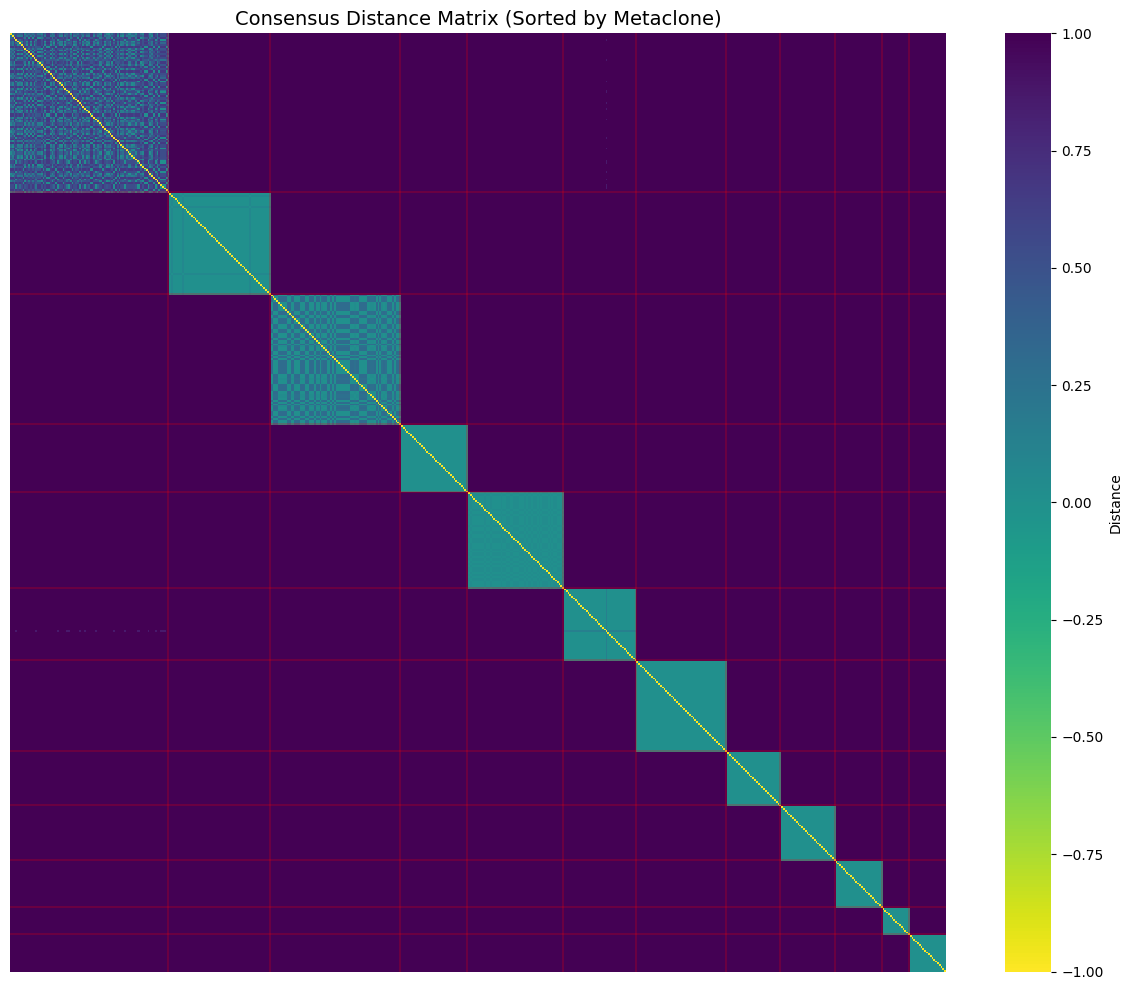

In [13]:
cc.plot_consensus_heatmap(consensus_distance, final_labels)
plt.show()

## 12. Summary

| Metric | Value |
|---|---|
| N ground-truth metaclones | 12 |
| N ChronoClone-detected metaclones | *(see cell 6)* |
| Adjusted Rand Index (ARI) | *(see cell 9)* |

**Interpretation:**
- ARI close to 1.0 confirms ChronoClone faithfully recovers the simulated metaclone structure.
- The confusion matrix should show a clean block-diagonal pattern.